# Live robot -> GR00T actions

Connect to the running Station daemon and policy server, capture one observation, request one action chunk, then execute its first 16 actions while displaying the live camera feed. Each requested joint target is clipped to `MAX_DELTA_TICKS` from its current position and kept within its calibrated range.

## 1. Import required libraries

In [1]:
import logging

import numpy as np
from IPython.display import display
from PIL import Image

from inference_client.frame import StationFrame
from inference_client.policy_client import PolicyClient

## 2. Connect to the live robot

Set the local paths and endpoints below. Install this package in the active kernel (`uv pip install -e .` from the repository root); `NORMA_CORE_PATH` must point to the norma-core checkout containing Station's Python modules and generated protobufs.

In [2]:
NORMA_CORE_PATH = "/home/del/robot-pizza-cup/elrobot/norma-core"
STATION_SERVER = "localhost"
POLICY_HOST, POLICY_PORT = "81.85.2.138", 5556
API_TOKEN = None  # Set only if the policy server requires authentication.
TASK = "move towards salami"
IMAGE_KEYS = ("cam0", "cam1")  # Match policy modality config and Frame image order.
STATE_KEY = "state"
BUS_SERIAL = "5B3D050348"  # Read from the Station web viewer.
MOTOR_IDS = [1, 2, 3, 4, 5, 6, 7, 8]  # Must match joint order.
TIMEOUT = 5.0
MAX_DELTA_TICKS = 100  # Clip each target to this maximum per-joint position change.

from inference_client.station_live import StationLink, add_norma_core_to_path, unnormalize_goal

add_norma_core_to_path(NORMA_CORE_PATH)
logger = logging.getLogger("live_robot_notebook")
logging.basicConfig(level=logging.INFO)

link = await StationLink.connect(STATION_SERVER, logger)
policy = PolicyClient(
    host=POLICY_HOST,
    port=POLICY_PORT,
    timeout_ms=int(TIMEOUT * 1000),
    api_token=API_TOKEN,
)
assert policy.ping(), f"Can't reach policy server at {POLICY_HOST}:{POLICY_PORT}"
modality_config = policy.get_modality_config()
print("Policy modality config:", modality_config)

INFO:live_robot_notebook:Connection established
INFO:live_robot_notebook:Initial setup successful


Policy modality config: {'video': {'delta_indices': [0], 'modality_keys': ['cam0', 'cam1', 'cam2'], 'sin_cos_embedding_keys': None, 'mean_std_embedding_keys': None, 'action_configs': None}, 'state': {'delta_indices': [0], 'modality_keys': ['state'], 'sin_cos_embedding_keys': None, 'mean_std_embedding_keys': None, 'action_configs': None}, 'action': {'delta_indices': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15], 'modality_keys': ['action'], 'sin_cos_embedding_keys': None, 'mean_std_embedding_keys': None, 'action_configs': [{'rep': 'ABSOLUTE', 'type': 'NON_EEF', 'format': 'DEFAULT', 'state_key': None}]}, 'language': {'delta_indices': [0], 'modality_keys': ['task'], 'sin_cos_embedding_keys': None, 'mean_std_embedding_keys': None, 'action_configs': None}}


## Preview all cameras

Station publishes more cameras than the policy uses. Run this to see one frame from each, in `Frame.images` order (index 0, 1, 2, ...), and decide which two match `cam0` / `cam1` from training. Set `IMAGE_KEYS` above accordingly. `to_observation` takes the first `len(IMAGE_KEYS)` images, so if the camera to drop is not the last one, Station's camera order has to change.

In [ ]:
reader, _ = await link.fetch_fresh_frame(b"", timeout=TIMEOUT)
preview = StationFrame.from_live(reader, task=TASK)
print(f"{len(preview.images)} cameras in Frame.images")
for i, img in enumerate(preview.images):
    used = IMAGE_KEYS[i] if i < len(IMAGE_KEYS) else "NOT USED by the policy"
    print(f"images[{i}] -> {used}")
    display(Image.fromarray(img.decode()))

## 3. Helper functions

Run these code cells from top to bottom to define the helpers, then run the final cell to capture one observation, request one action chunk, and execute it.

In [3]:
NUM_FUTURE_ACTIONS = 16


def request_action_chunk(observation, joint_count):
    action, info = policy.get_action(observation)
    if not action:
        raise ValueError("Policy returned no action arrays")

    action_values = np.asarray(next(iter(action.values())))
    if action_values.ndim != 3 or action_values.shape[0] != 1:
        raise ValueError(f"Expected action shape (1, chunk, joints), got {action_values.shape}")
    if action_values.shape[1] < NUM_FUTURE_ACTIONS:
        raise ValueError(f"Policy returned {action_values.shape[1]} actions; need {NUM_FUTURE_ACTIONS}")
    if action_values.shape[2] != joint_count:
        raise ValueError(f"Policy predicted {action_values.shape[2]} joints; live frame has {joint_count}")

    return action_values[0, :NUM_FUTURE_ACTIONS, :], info

In [4]:
def bounded_motor_goals(goal_norm, frame):
    if len(goal_norm) != len(frame.joints):
        raise ValueError(f"Action has {len(goal_norm)} joints; live frame has {len(frame.joints)}")

    goals = []
    clipped_count = 0
    for value, joint in zip(goal_norm, frame.joints):
        if not joint.range_min <= joint.position <= joint.range_max:
            raise ValueError(f"Current position {joint.position} is outside the calibrated range")

        requested = unnormalize_goal(value, joint.range_min, joint.range_max)
        lower = max(joint.range_min, joint.position - MAX_DELTA_TICKS)
        upper = min(joint.range_max, joint.position + MAX_DELTA_TICKS)
        bounded = max(lower, min(requested, upper))
        goals.append(bounded)
        clipped_count += requested != bounded

    return goals, clipped_count

In [5]:
async def execute_action_chunk(actions, frame_id, joint_count):
    if MAX_DELTA_TICKS <= 0:
        raise ValueError("MAX_DELTA_TICKS must be positive")
    if len(MOTOR_IDS) != joint_count:
        raise ValueError(f"Configured {len(MOTOR_IDS)} motor IDs for {joint_count} joints")

    reader, frame_id = await link.fetch_fresh_frame(frame_id, timeout=TIMEOUT)
    frame = StationFrame.from_live(reader, task=TASK)
    if not frame.images:
        raise ValueError("Station frame contains no camera images")
    camera_view = display(Image.fromarray(frame.images[0].decode()), display_id=True)

    for index, goal_norm in enumerate(actions):
        goals, clipped_count = bounded_motor_goals(goal_norm, frame)
        if clipped_count:
            print(f"action {index + 1}/{len(actions)}: clipped {clipped_count} joint targets")

        command = link.build_sync_write_command(BUS_SERIAL, MOTOR_IDS, goals)
        await link.send(command)

        reader, frame_id = await link.fetch_fresh_frame(frame_id, timeout=TIMEOUT)
        frame = StationFrame.from_live(reader, task=TASK)
        if not frame.images:
            raise ValueError("Station frame contains no camera images")
        camera_view.update(Image.fromarray(frame.images[0].decode()))
        print(f"executed action {index + 1}/{len(actions)}")
    else:
        print(f"completed all {len(actions)} actions")

In [6]:
async def run_live_policy_chunk():
    reader, frame_id = await link.fetch_fresh_frame(b"", timeout=TIMEOUT)
    frame = StationFrame.from_live(reader, task=TASK)
    observation = frame.to_observation(IMAGE_KEYS, STATE_KEY)
    print(f"captured {len(frame.joints)} joints and {len(frame.images)} images")

    actions, info = request_action_chunk(observation, len(frame.joints))
    print("policy info:", info)
    print(f"received {len(actions)} actions; executing them now")
    await execute_action_chunk(actions, frame_id, len(frame.joints))

INFO:live_robot_notebook:Read stream 122 started


captured 8 joints and 3 images


INFO:live_robot_notebook:Read stream 123 started


policy info: {}
received 16 actions; executing them now


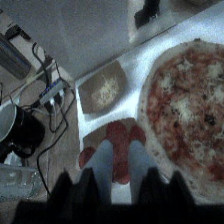

INFO:live_robot_notebook:Read stream 124 started


action 1/16: clipped 5 joint targets


INFO:live_robot_notebook:Read stream 125 started


executed action 1/16
action 2/16: clipped 5 joint targets
executed action 2/16
action 3/16: clipped 6 joint targets


INFO:live_robot_notebook:Read stream 126 started


...

executed action 16/16
completed all 16 actions


INFO:live_robot_notebook:Read stream 142 started


captured 8 joints and 3 images


INFO:live_robot_notebook:Read stream 143 started


policy info: {}
received 16 actions; executing them now


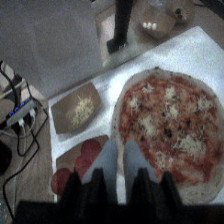

INFO:live_robot_notebook:Read stream 144 started


action 1/16: clipped 5 joint targets


INFO:live_robot_notebook:Read stream 145 started


executed action 1/16
action 2/16: clipped 5 joint targets
executed action 2/16
action 3/16: clipped 7 joint targets


INFO:live_robot_notebook:Read stream 146 started


...

executed action 15/16
action 16/16: clipped 4 joint targets


INFO:live_robot_notebook:Read stream 161 started
INFO:live_robot_notebook:Read stream 162 started


executed action 16/16
completed all 16 actions
captured 8 joints and 3 images


INFO:live_robot_notebook:Read stream 163 started


policy info: {}
received 16 actions; executing them now


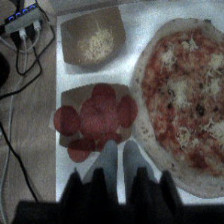

INFO:live_robot_notebook:Read stream 164 started
INFO:live_robot_notebook:Read stream 165 started


action 1/16: clipped 6 joint targets
executed action 1/16
action 2/16: clipped 4 joint targets


INFO:live_robot_notebook:Read stream 166 started
INFO:live_robot_notebook:Read stream 167 started


executed action 2/16
action 3/16: clipped 5 joint targets


INFO:live_robot_notebook:Read stream 168 started


...

executed action 16/16
completed all 16 actions


INFO:live_robot_notebook:Read stream 183 started


captured 8 joints and 3 images


INFO:live_robot_notebook:Read stream 184 started


policy info: {}
received 16 actions; executing them now


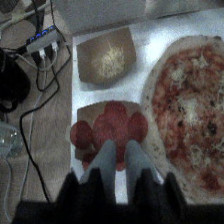

INFO:live_robot_notebook:Read stream 185 started
INFO:live_robot_notebook:Read stream 186 started


action 1/16: clipped 4 joint targets
executed action 1/16
action 2/16: clipped 5 joint targets


INFO:live_robot_notebook:Read stream 187 started
INFO:live_robot_notebook:Read stream 188 started


executed action 2/16
action 3/16: clipped 4 joint targets
executed action 3/16
action 4/16: clipped 3 joint targets


INFO:live_robot_notebook:Read stream 189 started


...

executed action 15/16
action 16/16: clipped 5 joint targets


INFO:live_robot_notebook:Read stream 202 started
INFO:live_robot_notebook:Read stream 203 started
INFO:live_robot_notebook:Read stream 204 started


executed action 16/16
completed all 16 actions
captured 8 joints and 3 images


INFO:live_robot_notebook:Read stream 205 started


policy info: {}
received 16 actions; executing them now


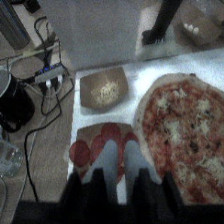

INFO:live_robot_notebook:Read stream 206 started


action 1/16: clipped 4 joint targets


INFO:live_robot_notebook:Read stream 207 started


executed action 1/16
action 2/16: clipped 4 joint targets
executed action 2/16
action 3/16: clipped 3 joint targets


INFO:live_robot_notebook:Read stream 208 started


...

executed action 16/16
completed all 16 actions


INFO:live_robot_notebook:Read stream 224 started


captured 8 joints and 3 images


INFO:live_robot_notebook:Read stream 225 started


policy info: {}
received 16 actions; executing them now


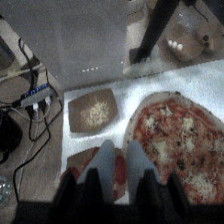

INFO:live_robot_notebook:Read stream 226 started


action 1/16: clipped 3 joint targets


INFO:live_robot_notebook:Read stream 227 started


executed action 1/16
action 2/16: clipped 5 joint targets
executed action 2/16
action 3/16: clipped 4 joint targets


INFO:live_robot_notebook:Read stream 228 started


...

executed action 15/16
action 16/16: clipped 4 joint targets


INFO:live_robot_notebook:Read stream 242 started
INFO:live_robot_notebook:Read stream 243 started
INFO:live_robot_notebook:Read stream 244 started


executed action 16/16
completed all 16 actions
captured 8 joints and 3 images


INFO:live_robot_notebook:Read stream 245 started


policy info: {}
received 16 actions; executing them now


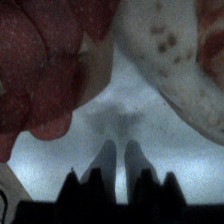

INFO:live_robot_notebook:Read stream 246 started
INFO:live_robot_notebook:Read stream 247 started


action 1/16: clipped 4 joint targets
executed action 1/16
action 2/16: clipped 3 joint targets


INFO:live_robot_notebook:Read stream 248 started
INFO:live_robot_notebook:Read stream 249 started


executed action 2/16
action 3/16: clipped 5 joint targets
executed action 3/16
action 4/16: clipped 3 joint targets


INFO:live_robot_notebook:Read stream 250 started


...

executed action 15/16
action 16/16: clipped 5 joint targets


INFO:live_robot_notebook:Read stream 279 started


executed action 16/16
completed all 16 actions
captured 8 joints and 3 images


INFO:live_robot_notebook:Read stream 280 started


policy info: {}
received 16 actions; executing them now


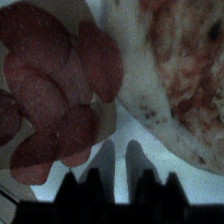

INFO:live_robot_notebook:Read stream 281 started


action 1/16: clipped 6 joint targets


INFO:live_robot_notebook:Read stream 282 started


executed action 1/16
action 2/16: clipped 5 joint targets


INFO:live_robot_notebook:Read stream 283 started


...

executed action 16/16
completed all 16 actions


INFO:live_robot_notebook:Read stream 299 started


captured 8 joints and 3 images


INFO:live_robot_notebook:Read stream 300 started


policy info: {}
received 16 actions; executing them now


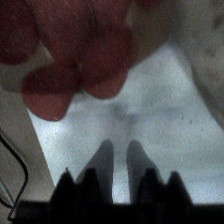

INFO:live_robot_notebook:Read stream 301 started


action 1/16: clipped 6 joint targets


INFO:live_robot_notebook:Read stream 302 started


executed action 1/16
action 2/16: clipped 3 joint targets
executed action 2/16
action 3/16: clipped 5 joint targets


INFO:live_robot_notebook:Read stream 303 started


...

executed action 15/16
action 16/16: clipped 4 joint targets


INFO:live_robot_notebook:Read stream 317 started
INFO:live_robot_notebook:Read stream 318 started
INFO:live_robot_notebook:Read stream 319 started


executed action 16/16
completed all 16 actions
captured 8 joints and 3 images


INFO:live_robot_notebook:Read stream 320 started


policy info: {}
received 16 actions; executing them now


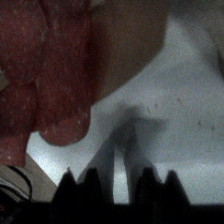

INFO:live_robot_notebook:Read stream 321 started
INFO:live_robot_notebook:Read stream 322 started


action 1/16: clipped 3 joint targets
executed action 1/16
action 2/16: clipped 6 joint targets


INFO:live_robot_notebook:Read stream 323 started
INFO:live_robot_notebook:Read stream 324 started


executed action 2/16
action 3/16: clipped 5 joint targets
executed action 3/16
action 4/16: clipped 4 joint targets


INFO:live_robot_notebook:Read stream 325 started


...

executed action 13/16
action 14/16: clipped 5 joint targets


INFO:live_robot_notebook:Read stream 336 started
INFO:live_robot_notebook:Read stream 337 started


executed action 14/16
action 15/16: clipped 5 joint targets


INFO:live_robot_notebook:Read stream 338 started
INFO:live_robot_notebook:Read stream 339 started


executed action 15/16
action 16/16: clipped 4 joint targets
executed action 16/16
completed all 16 actions


In [9]:
for i in range(10):
    await run_live_policy_chunk()

## Close the policy client

Run when finished. Restart the kernel before reconnecting if you need to recreate the Station connection.

In [10]:
policy.close()